In [29]:
# %%
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import h5py
import os
import json

import pickle
import os


import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint

from tensorflow.keras.callbacks import EarlyStopping

import matplotlib.pyplot as plt
import numpy as np




import model_architecture as model_arch
import helper

In [30]:
# Dynamic GPU memory allocation: For local prototyping, don't block GPU
config = tf.compat.v1.ConfigProto()
config.gpu_options.allow_growth = True
sess = tf.compat.v1.Session(config=config)

2026-07-01 16:37:21.080165: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-07-01 16:37:21.080935: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-07-01 16:37:21.081132: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-07-01 16:37:21.083500: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:06:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-07-01 16:37:21.083580: I tensorflow/core/common_runtime/gpu/gpu

In [31]:
data_path = 'datasets/2026_04_15_full_pisa_data.h5'

# load data and scalers
x_train, x_test, y_train, y_test, wavelengths = helper.load_data_from_h5(
    data_path,
    condition_name='R',
    input_name='geo',
    save_scalers=True) # Save scalers for first time

In [32]:
with h5py.File(data_path) as f_read:
    inputs = np.array(f_read['geo'], dtype=np.float32)#[:, 35:110]
    conditions = np.array(f_read['R'], dtype=np.float32)#[:, 35:110] 
    frequencies = np.array(f_read['wavelengths'], dtype=np.float32)#[35:110]

In [33]:
conditions.shape

(9800, 161)

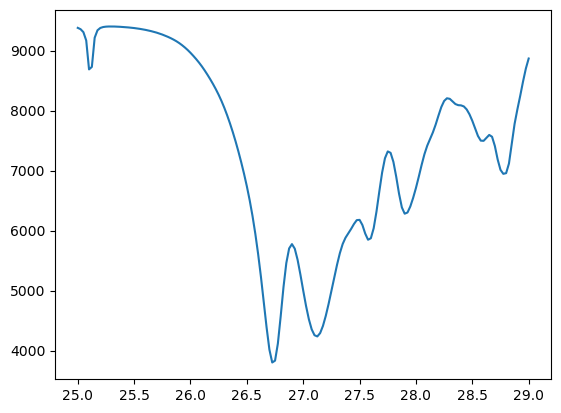

In [34]:
conditionsum = conditions.sum(axis=0)
fig, ax1 = plt.subplots()

ax1.plot(frequencies, conditionsum)
plt.show()

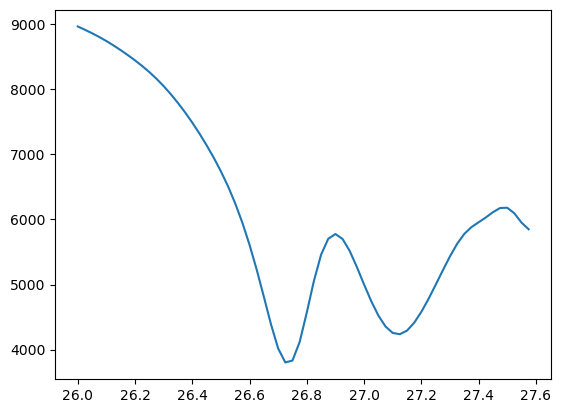

In [35]:
conditionsum = conditions[:, 40:104].sum(axis=0)
fig, ax1 = plt.subplots()

ax1.plot(frequencies[40:104], conditionsum)
plt.show()

In [36]:
def create_reflectance_target(frequencies, center_freq, width, depth, order=2):
    """
    Generates a design target with a super-Gaussian (flattop) dip.

    Args:
        frequencies (np.ndarray): The array of frequency points.
        center_freq (float): The center frequency for the dip.
        width (float): The full width at half maximum (FWHM) of the dip.
        depth (float): The maximum depth of the dip (e.g., 1.0 for a dip to 0).
        order (float): The order of the super-Gaussian. 2 is a standard
                       Gaussian. Higher values create a flatter bottom.

    Returns:
        np.ndarray: The target reflectance spectrum.
    """
    # The baseline reflectance is 1.
    baseline = np.ones_like(frequencies)

    # Gaussian function to create a flatter dip.
    # The relationship between FWHM and standard deviation (sigma) is
    # maintained from the standard Gaussian to keep the 'width' parameter intuitive.
    sigma = width / (2 * np.sqrt(2 * np.log(2)))
    
    # Calculate Gaussian dip.
    # The 'order' parameter controls the flatness of the dip's bottom.
    flattop_dip = depth * np.exp(-(np.abs((frequencies - center_freq) / (np.sqrt(2) * sigma)))**order)

    # Subtract the dip from the baseline to get the final target.
    target_reflectance = baseline - flattop_dip
    
    return target_reflectance

In [37]:
target = create_reflectance_target(frequencies, center_freq=26, width=0.1, depth=0.5, order=2) - 0.05

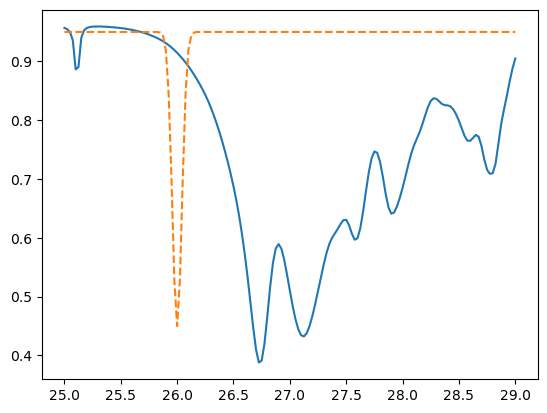

In [38]:
conditionmean = conditions.mean(axis=0)
fig, ax1 = plt.subplots()
ax1.plot(frequencies, conditionmean)
ax1.plot(frequencies, target, label='Target Reflectance', linestyle='--')
plt.show()   


In [39]:
# Monty carlo test to find the best initial geometry for the target reflectance

# lowest_loss = 10000.0

# lowest_loss_index = -1

# #while lowest_loss > 0.01:

# for indx in range(conditions.shape[0]):

#     spectra = conditions[indx]

#     loss = np.mean((spectra - target) ** 2)
#     if loss < lowest_loss:
#         lowest_loss = loss
#         lowest_loss_index = indx

# print(lowest_loss, lowest_loss_index)

# plt.plot(frequencies, conditions[lowest_loss_index], label='Best Initial Geometry')
# plt.plot(frequencies, target, label='Target Reflectance', linestyle='--')
# plt.legend()
# plt.show()

In [40]:
conditions.shape

(9800, 161)

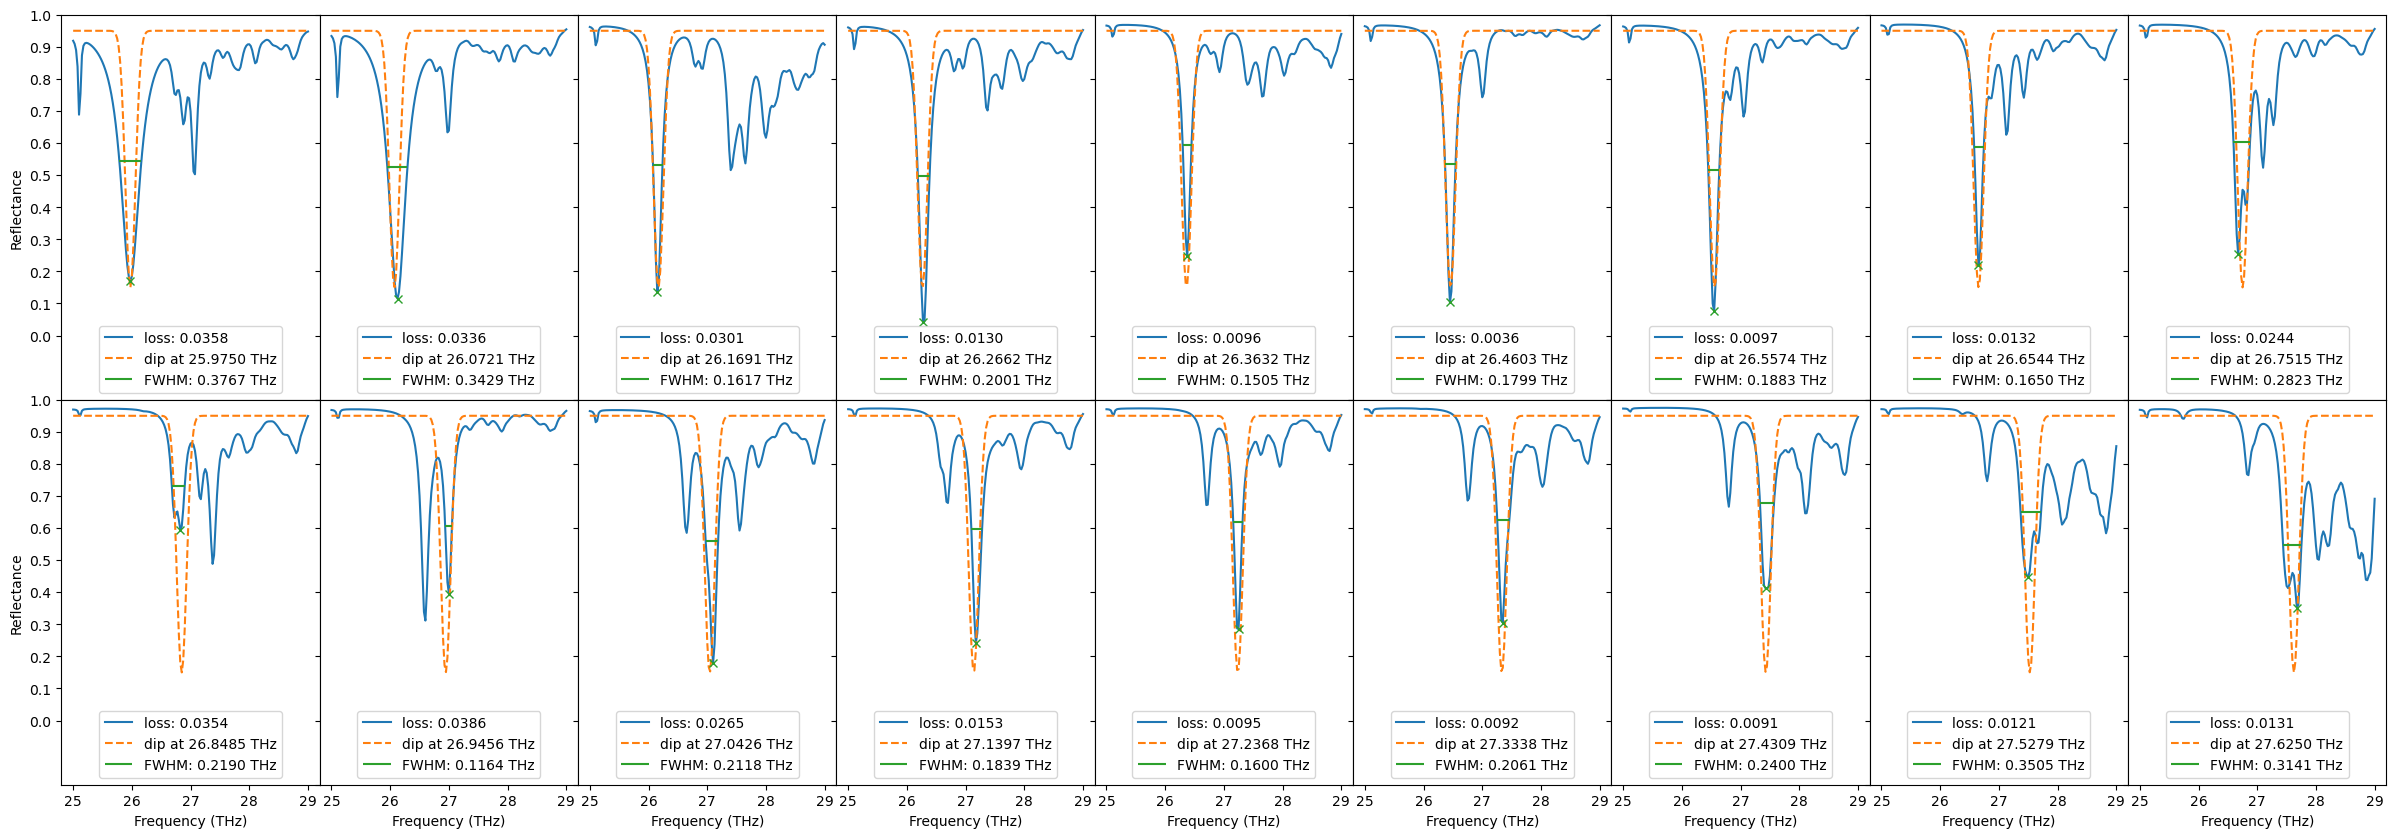

Dataset Shape (samples, spectra points):
(9800, 161)
Frequency Range:
25.875 to 27.725 THz
Mean width:  0.2249575548376445
Mean prominence:  0.664251039425532
Mean linewidth ratio:  0.05623938870941113


In [46]:

from math import ceil

from scipy.signal import peak_widths, peak_prominences

# frequency_targets = np.arange(frequencies.min()+0.1, frequencies.max()-0.1, 0.2)
frequency_targets = np.linspace(25.875+0.1, 27.725-0.1, 18)

min_freq = 25.875 #frequencies.min()
max_freq = 27.725 #frequencies.max()

frequency_step = frequencies[1] - frequencies[0]



half = ceil(frequency_targets.shape[0]/2)

fig, ax1 = plt.subplots(2, half, figsize=(30, 10))

all_widths = []
all_prominences = []
for index, i in enumerate(frequency_targets):
    target = create_reflectance_target(frequencies, center_freq=i, width=0.2, depth=0.8, order=2) - 0.05
    conditionmean = conditions.mean(axis=0)

    lowest_loss = 10000.0

    lowest_loss_index = -1

    #while lowest_loss > 0.01:

    for indx in range(conditions.shape[0]):

        spectra = conditions[indx]

        loss = np.mean((spectra[35:110] - target[35:110]) ** 2)
        if loss < lowest_loss:
            lowest_loss = loss
            lowest_loss_index = indx

    # print(lowest_loss, lowest_loss_index)

    best_fit = 1 - conditions[lowest_loss_index]

    #print(best_fit.shape)


    peak_area = np.where(target < 0.9)[0]

    best_fit_area = conditions[lowest_loss_index][peak_area]

    first_index =  peak_area[0]

    # print(frequencies.shape)

    # print(np.where(frequencies == i))
    peak_index = best_fit_area.argmin() + first_index# np.abs(frequencies - i).argmin() # np.where(frequencies == i)[0][0]

    prominences = peak_prominences(best_fit, np.array([peak_index]))


    widths, width_heights, left_ips, right_ips = peak_widths(best_fit, np.array([peak_index]), prominence_data=prominences, rel_height=0.5)
    
    width = widths[0] * frequency_step

    # print(frequency_step)

    all_widths.append(width)
    all_prominences.append(prominences[0])



    # left_ips, right_ips = widths_half[2][0], widths_half[2][1]

    left_freqs = np.interp(left_ips, np.arange(len(frequencies)), frequencies)
    right_freqs = np.interp(right_ips, np.arange(len(frequencies)), frequencies)



    plt.subplots_adjust(hspace=0, wspace=0)


    if index == 0:
        ax1[0, index].plot(frequencies, conditions[lowest_loss_index], label=f'loss: {lowest_loss:.4f}')
        ax1[0, index].plot(frequencies, target, label=f'dip at {i:.4f} THz', linestyle='--')

        ax1[0, index].plot(frequencies[peak_index], conditions[lowest_loss_index][peak_index], 'x')
        
        ax1[0, index].hlines(1 - width_heights, left_freqs, right_freqs, color="C2", label=f"FWHM: {width:.4f} THz")


        ax1[0, index].set_ylabel('Reflectance')
        ax1[0, index].set_xticklabels(())
        ax1[0, index].set_yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
        ax1[0, index].set_ylim([-0.2, 1])
        ax1[0, index].legend(loc='lower center')

    elif index < half:
        ax1[0, index].plot(frequencies, conditions[lowest_loss_index], label=f'loss: {lowest_loss:.4f}')
        ax1[0, index].plot(frequencies, target, label=f'dip at {i:.4f} THz', linestyle='--')

        ax1[0, index].plot(frequencies[peak_index], conditions[lowest_loss_index][peak_index], 'x')
        
        ax1[0, index].hlines(1 - width_heights, left_freqs, right_freqs, color="C2", label=f"FWHM: {width:.4f} THz")

        ax1[0, index].set_yticklabels(())
        ax1[0, index].set_xticklabels(())
        ax1[0, index].set_ylim([-0.2, 1])
        ax1[0, index].legend(loc='lower center')

    elif index == half:
        ax1[1, 0].plot(frequencies, conditions[lowest_loss_index], label=f'loss: {lowest_loss:.4f}')
        ax1[1, 0].plot(frequencies, target, label=f'dip at {i:.4f} THz', linestyle='--')

        ax1[1, 0].plot(frequencies[peak_index], conditions[lowest_loss_index][peak_index], 'x')
        
        ax1[1, 0].hlines(1 - width_heights, left_freqs, right_freqs, color="C2", label=f"FWHM: {width:.4f} THz")

        ax1[1, 0].set_xlabel('Frequency (THz)')
        ax1[1, 0].set_ylabel('Reflectance')
        ax1[1, 0].set_yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
        ax1[1, 0].set_ylim([-0.2, 1]) 
        ax1[1, 0].legend(loc='lower center') 
    else:
        ax1[1, index-half].plot(frequencies, conditions[lowest_loss_index], label=f'loss: {lowest_loss:.4f}')
        ax1[1, index-half].plot(frequencies, target, label=f'dip at {i:.4f} THz', linestyle='--')

        ax1[1, index-half].plot(frequencies[peak_index], conditions[lowest_loss_index][peak_index], 'x')
        
        ax1[1, index-half].hlines(1 - width_heights, left_freqs, right_freqs, color="C2", label=f"FWHM: {width:.4f} THz")

        ax1[1, index-half].set_xlabel('Frequency (THz)')
        ax1[1, index-half].set_yticklabels(())
        ax1[1, index-half].set_ylim([-0.2, 1])
        ax1[1, index-half].legend(loc='lower center')

# plt.legend()
plt.savefig(f'best_spectra_vs_target_{frequencies.min()}_to_{frequencies.max()}.png', dpi=300)
plt.show()



mean_width = np.mean(all_widths)
mean_prominence = np.mean(all_prominences)

linewidth_ratio = mean_width / (frequencies.max() - frequencies.min())

print("Dataset Shape (samples, spectra points):")
print(conditions.shape)
print("Frequency Range:")
print(min_freq, "to", max_freq, "THz")
print("Mean width: ", mean_width)
print("Mean prominence: ", mean_prominence)
print("Mean linewidth ratio: ", linewidth_ratio)
    

In [59]:
print("Dataset Shape (samples, spectra points):")
print(conditions.shape)
print("Frequency Range:")
print(frequencies.min(), "to", frequencies.max(), "THz")

Dataset Shape (samples, spectra points):
(9800, 75)
Frequency Range:
25.875 to 27.725 THz
